In [1]:
import SimpleITK as sitk
import matplotlib.pyplot as plt
from pathlib import Path
import numpy as np


import sys
sys.path.insert(0, "/workspace/segmentation")
from tools import img_show3D, window, img_show2D


In [2]:
# image = np.array([
#     [10, 20, 30],
#     [20, 30, 40],
#     [30, 40, 50],
# ], dtype=np.float32)

In [3]:
# spacing_x = 1.0
# spacing_y = 1.0


In [4]:
# sitk_image = sitk.GetImageFromArray(image)
# sitk_image.SetSpacing((spacing_x, spacing_y))

In [5]:
def cast(img):
    width, height = img.GetSize()

    for y in range(height):
        for x in range(width):
            print(img[x, y], end=" ")
        print()  # Start a new line after each row.

In [6]:
# cast(sitk_image)

In [7]:
gradient_filter = sitk.GradientImageFilter()
gradient_filter.SetUseImageSpacing(True)
gradient_filter.SetUseImageDirection(False)



In [8]:
# gradient = gradient_filter.Execute(sitk_image)

In [9]:
# gradient.GetSize()

In [10]:
# gradient.GetNumberOfComponentsPerPixel()

In [11]:
# cast(gradient)

In [12]:
# gx = sitk.VectorIndexSelectionCast(gradient, 0)
# gy = sitk.VectorIndexSelectionCast(gradient, 1)

In [13]:
# cast(gx)

In [14]:
# gradient_magnitude = sitk.Sqrt(
#     gx * gx + gy * gy
# )

In [15]:
# cast(gradient_magnitude)

In [16]:
img_dir = Path ("/workspace/segmentation/data/practice/image_quadra/QUADRA_HC_021/retest_CT-AC.nii.gz")
img = sitk.ReadImage(img_dir)

mask_dir = Path ("/workspace/segmentation/data/practice/mask_quadra/QUADRA_HC_021/retest/liver.nii.gz")
mask = sitk.ReadImage(mask_dir)

In [17]:
sigma = 1

smooting_filter = sitk.SmoothingRecursiveGaussianImageFilter()
smooting_filter.SetSigma(sigma)

smooth_img = smooting_filter.Execute(img)

In [18]:
def crop_img_mask (img, mask):

    padding = 10

    stats = sitk.LabelShapeStatisticsImageFilter()
    stats.Execute(mask)
    x_start, y_start, z_start, x_size, y_size, z_size = stats.GetBoundingBox(1)
    x_end = x_start + x_size - 1
    y_end = y_start + y_size - 1
    z_end = z_start + z_size - 1

    img_cut = img[x_start - padding: x_end + padding, y_start - padding: y_end + padding, z_start - padding: z_end + padding]
    mask_cut = mask[x_start - padding: x_end + padding, y_start - padding: y_end + padding, z_start - padding: z_end + padding]

    return img_cut, mask_cut



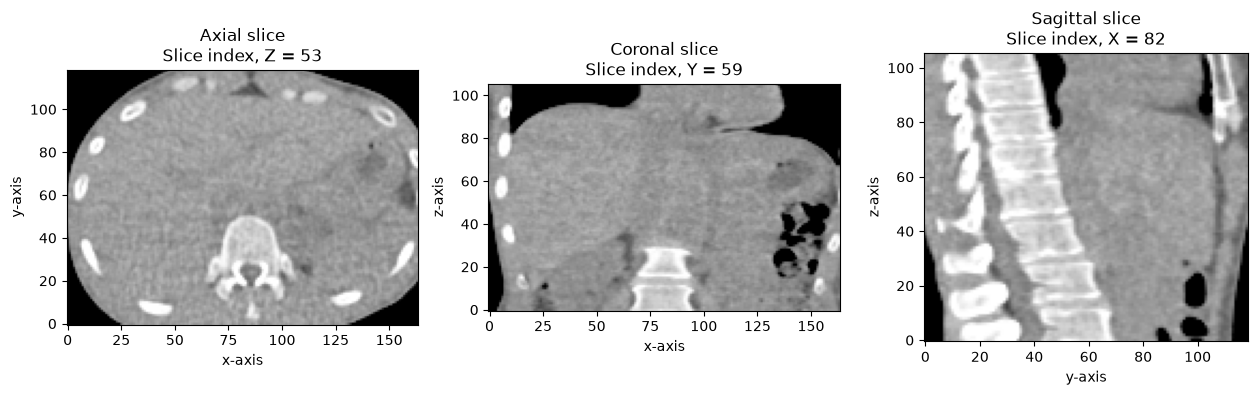

In [19]:
smooth_img_win = window (smooth_img, window_width = 400, window_center = 40)
crop_img, crop_mask = crop_img_mask(smooth_img_win, mask)
img_show3D (crop_img, scale = 3)

In [20]:
gradient_img = gradient_filter.Execute(smooth_img)

In [21]:
gradient_x = sitk.VectorIndexSelectionCast(gradient_img, 0)
gradient_y = sitk.VectorIndexSelectionCast(gradient_img, 1)
gradient_z = sitk.VectorIndexSelectionCast(gradient_img, 2)

In [22]:
#calculate the gradient maginitude for each foxel

# grad_magnitude = sitk.Sqrt(
#     gradient_x ** 2 + gradient_y ** 2 + gradient_z ** 2
# )

In [23]:
# print (
#     grad_magnitude.GetSize(),
#     grad_magnitude.GetNumberOfComponentsPerPixel()
# )

In [24]:
# #display gradient magnitude
# crop_img, crop_mask = crop_img_mask(grad_magnitude, mask)
# img_show3D (crop_img, scale = 5, mask = crop_mask, alpha= 0.05)

In [26]:
# #display the windowed gradient magnitude
# gradient_img_win = window (grad_magnitude, window_width = 400, window_center = 40)
# crop_img, crop_mask = crop_img_mask(gradient_img_win, mask)
# img_show3D (crop_img, scale = 5, mask = crop_mask, alpha= 0.05)

calculating harris response


R = det(M)-k(trace(M))^3.

M = (
    {gxgx} {gxgy} {gxgz} 
    {gxgy} {gygy} {gygz}
    {gxgz} {gygz} {gzgz}
)

{g} = gaussian smooth g

trace(M) = {gx^2} + {gy^2} + {gy^2}





In [27]:
sigma = 1

gaussian_harris = sitk.SmoothingRecursiveGaussianImageFilter()
gaussian_harris.SetSigma(sigma)

for 

M = [
    A B C
    B D E
    C E F
]

det(M) = ADF + 2BCE - AE^2 - DC^2 - FB^2

A = {gxgx}
B = {gxgy}
C = {gxgz}
D = {gygy}
E = {gygz}
F = {gzgz}



In [28]:
A = gaussian_harris.Execute(gradient_x * gradient_x)
B = gaussian_harris.Execute(gradient_x * gradient_y)
C = gaussian_harris.Execute(gradient_x * gradient_z)
D = gaussian_harris.Execute(gradient_y * gradient_y)
E = gaussian_harris.Execute(gradient_y * gradient_z)
F = gaussian_harris.Execute(gradient_z * gradient_z)

In [29]:
det_M = A*D*F + 2.0*B*C*E - A*E*E - D*C*C - F*B*B

In [30]:
det_M.GetSize()

(512, 512, 531)

In [31]:
det_M.GetNumberOfComponentsPerPixel()

1

In [32]:
trace_M = A + D + F

In [33]:
trace_M.GetSize()

(512, 512, 531)

In [34]:
trace_M.GetNumberOfComponentsPerPixel()

1

In [35]:
k = 0.005
harris_response = det_M - k * trace_M * trace_M * trace_M

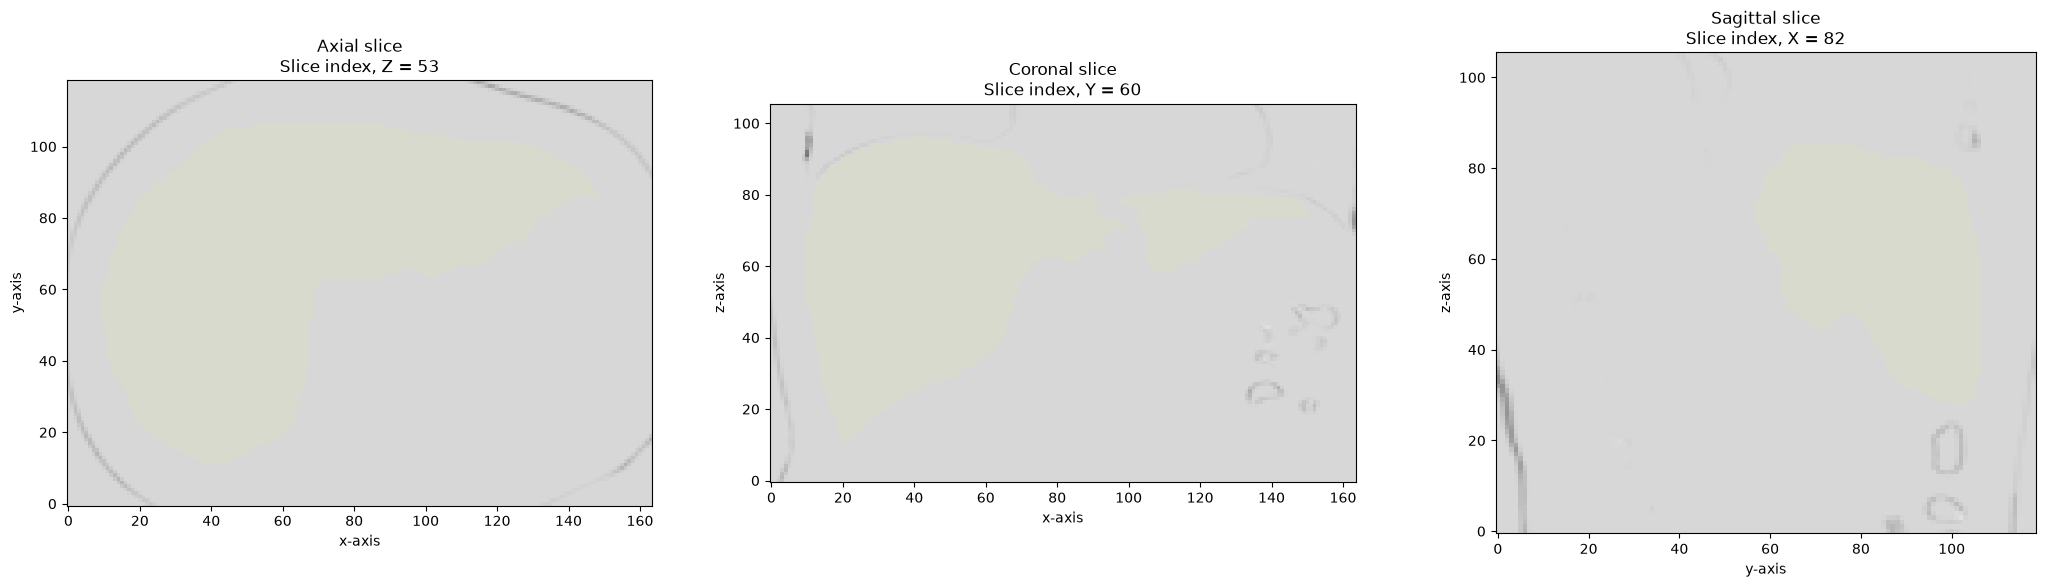

In [ ]:
# crop_img, crop_mask = crop_img_mask(harris_response, mask)
# img_show3D (crop_img, scale = 5, mask = crop_mask, alpha= 0.1)

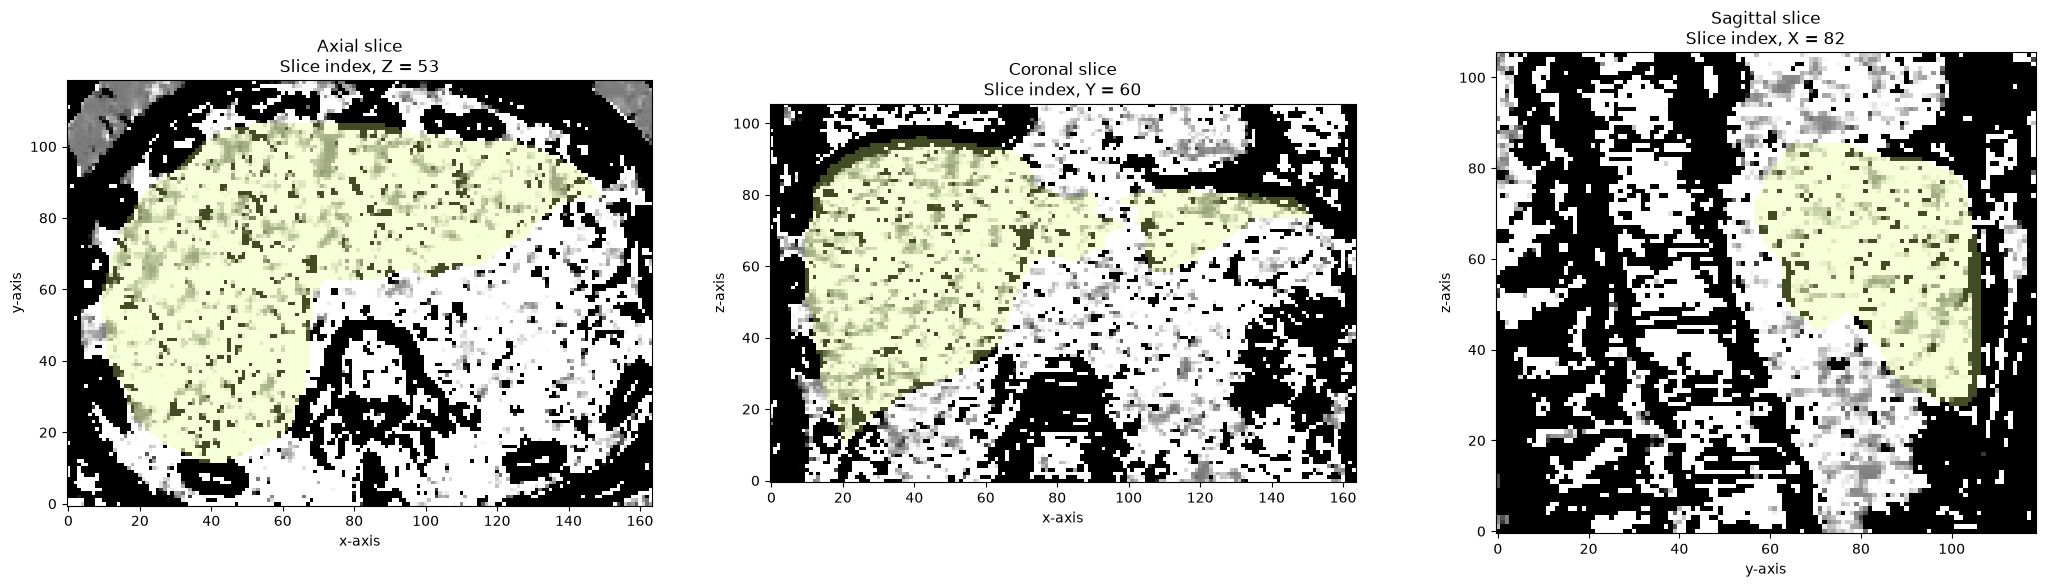

In [36]:
respon_win = window (harris_response, window_width = 400, window_center = 40)
crop_img, crop_mask = crop_img_mask(respon_win, mask)
img_show3D (crop_img, scale = 5, mask = crop_mask, alpha= 0.3)

In [ ]:
def show_range(name, image):
    stats = sitk.StatisticsImageFilter()
    stats.Execute(image)
    print(
        name,
        "min:", stats.GetMinimum(),
        "max:", stats.GetMaximum(),
        "mean:", stats.GetMean(),
    )

In [ ]:
show_range("trace", trace_M)
show_range("determinant", det_M)
show_range("grad_x", gradient_x)
show_range("grad_y", gradient_y)
show_range("grad_z", gradient_z)

trace min: -950.7310791015625 max: 1166310.375 mean: 1642.3683275249587
determinant min: -42394902528.0 max: 1.2468823709974528e+16 mean: 3839301730.5529976
grad_x min: -784.1114501953125 max: 1067.069091796875 mean: 0.0005154888792960776
grad_y min: -1071.781494140625 max: 846.2250366210938 mean: 1.2897326036250287e-05
grad_z min: -826.0765380859375 max: 909.7394409179688 mean: -0.06797493686803813


In [38]:
laplacian_filter = sitk.LaplacianRecursiveGaussianImageFilter()
laplacian_filter.SetSigma(1.0)


In [39]:
laplacian_raw = laplacian_filter.Execute(harris_response)
laplacian_win = laplacian_filter.Execute(respon_win)

: 